In [1]:
import numpy as np
import matplotlib.pyplot as plt
import gc

In [2]:
maps = np.load("/project/ag-weller/Kai.Lehman/C3NN_data/kappa_noiseless_fiducial_cosmology_150_maps_50_by_50pixels_6_by_6deg_no_smooth_4_des_zsbin_gnom_projection.npy")

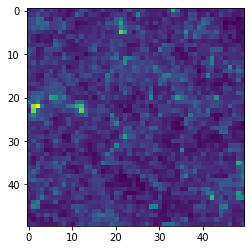

In [28]:
plt.imshow(maps[0,3])

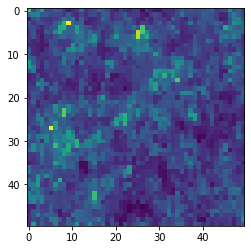

In [29]:
plt.imshow(maps[3,3])

In [4]:
def randomize_phase_2d_batched(
    maps_5d, 
    batch_size=50,  # Adjust based on your RAM (smaller = less memory)
    use_float32=True  # Cut memory usage in half (safe for most cosmological data)
):
    """
    Memory-optimized phase randomization with batch processing.
    Processes small batches to avoid large contiguous memory allocations.
    
    Args:
        maps_5d (np.ndarray): 5D array (nodes, maps, bins, H, W)
        batch_size (int): Number of nodes to process per batch (smaller = less memory)
        use_float32 (bool): Use float32/complex64 (vs float64/complex128) for memory savings
    
    Returns:
        np.ndarray: Phase-randomized maps (same shape as input, float32/float64)
    """
    # Validate input
    assert len(maps_5d.shape) == 5, "Input must be 5D (nodes, maps, bins, H, W)"
    n_nodes, n_maps, n_bins, H, W = maps_5d.shape
    assert H == W, "Maps must be square"
    
    # Convert input to float32 if requested (cuts memory in half)
    dtype = np.float32 if use_float32 else np.float64
    complex_dtype = np.complex64 if use_float32 else np.complex128
    maps_5d = maps_5d.astype(dtype, copy=False)  # In-place conversion (no extra copy)
    
    # Initialize output array (pre-allocate to avoid reallocations)
    output = np.empty_like(maps_5d, dtype=dtype)
    
    # Process in batches (loop over nodes)
    n_batches = (n_nodes + batch_size - 1) // batch_size  # Ceiling division
    for batch_idx in range(n_batches):
        # Get batch slice (e.g., 0-49, 50-99, ...)
        start = batch_idx * batch_size
        end = min((batch_idx + 1) * batch_size, n_nodes)
        batch = maps_5d[start:end]
        
        # Step 1: 2D FFT (last two axes) with explicit dtype
        fft_batch = np.fft.fft2(batch, axes=(-2, -1))
        fft_batch_shifted = np.fft.fftshift(fft_batch, axes=(-2, -1))
        
        # Step 2: Preserve amplitude, randomize phase (skip zero-frequency)
        amplitude = np.abs(fft_batch_shifted)
        random_phase = np.random.uniform(0, 2 * np.pi, size=amplitude.shape).astype(dtype)
        
        # Exclude zero-frequency component (center pixel) from phase randomization
        cx, cy = H // 2, W // 2
        random_phase[..., cx, cy] = 0.0  # Phase = 0 (no change)
        
        # Reconstruct FFT (amplitude * e^(i*phase))
        fft_phase_random = amplitude * np.exp(1j * random_phase.astype(complex_dtype))
        
        # Step 3: Inverse FFT
        fft_phase_random_unshifted = np.fft.ifftshift(fft_phase_random, axes=(-2, -1))
        ifft_batch = np.fft.ifft2(fft_phase_random_unshifted, axes=(-2, -1))
        
        # Step 4: Extract real part and save to output
        output[start:end] = np.real(ifft_batch)
        
        # Step 5: Free memory (critical for large batches)
        del batch, fft_batch, fft_batch_shifted, amplitude, random_phase
        del fft_phase_random, fft_phase_random_unshifted, ifft_batch
        gc.collect()  # Force garbage collector to free unused memory
        
        # Progress update
        print(f"Processed batch {batch_idx+1}/{n_batches} (nodes {start}-{end-1})")
    
    return output

def randomize_phase_2d(maps_5d):
    """
    Apply 2D FFT to each square map, randomize phase, and inverse FFT back to real space.
    
    Args:
        maps_5d (np.ndarray): 5D array with shape (n_nodes, n_maps_per_node, n_bins, height, width)
    
    Returns:
        np.ndarray: 5D array of phase-randomized real-space maps (same shape as input)
    """
    # Step 1: Validate input shape
    assert len(maps_5d.shape) == 5, "Input must be a 5D array (nodes, maps, bins, H, W)"
    n_nodes, n_maps, n_bins, H, W = maps_5d.shape
    assert H == W, "Maps must be square (height == width)"
    
    # Step 2: Apply 2D FFT to each map (last two dimensions: height/width)
    # fft2 operates on the last two axes; fftshift centers the zero frequency component
    fft_maps = np.fft.fft2(maps_5d, axes=(-2, -1))  # Shape: (1250, 150, 4, 50, 50) (complex)
    fft_maps_shifted = np.fft.fftshift(fft_maps, axes=(-2, -1))  # Center FFT (optional but intuitive)
    
    # Step 3: Compute amplitude (magnitude) and randomize phase
    # Amplitude: preserve the original magnitude of FFT components
    amplitude = np.abs(fft_maps_shifted)
    
    # Random phase: uniform in [0, 2π) for all FFT components (same shape as amplitude)
    # Use a fixed seed for reproducibility (remove/change seed if needed)
    np.random.seed(42)
    random_phase = np.random.uniform(0, 2 * np.pi, size=amplitude.shape)
    
    # Reconstruct FFT with original amplitude + random phase (complex form: A * e^(iφ))
    fft_phase_random = amplitude * np.exp(1j * random_phase)
    
    # Step 4: Inverse shift (undo fftshift) and inverse FFT
    fft_phase_random_unshifted = np.fft.ifftshift(fft_phase_random, axes=(-2, -1))
    ifft_maps = np.fft.ifft2(fft_phase_random_unshifted, axes=(-2, -1))
    
    # Step 5: Convert back to real space (discard tiny imaginary parts from numerical error)
    real_maps = np.real(ifft_maps)
    
    return real_maps

In [15]:
fft_maps = np.fft.fft2(maps, axes=(-2, -1))  # Shape: (1250, 150, 4, 50, 50) (complex)
print(fft_maps[0,0,1,1])

(-0.004494562060365047+0.47029843514524j)


In [5]:
print("Starting phase randomization...")
phase_randomized_maps = randomize_phase_2d_batched(np.expand_dims(maps,axis=0), batch_size=50, use_float32=False)

# Verify output shape and realness
print(f"Input shape: {maps.shape}")
print(f"Output shape: {phase_randomized_maps.shape}")
# Check 1: Double FFT/IFFT of input is real (fixed syntax)
print(f"Input FFT/IFFT round-trip is real: {np.allclose(np.imag(np.fft.ifft2(np.fft.fft2(maps))), 0)}")

# Check 2: Phase-randomized output has negligible imaginary parts (key check)
print(f"Phase-randomized maps are real (imaginary parts ~0): {np.allclose(np.imag(phase_randomized_maps), 0, atol=1e-10)}")

#np.save('/e/ocean1/users/lgong/CCNN/cosmogrid/kappa_noiseless_1250_wide_grid_cosmologies_150_maps_50_by_50pixels_6_by_6deg_no_smooth_4_des_zsbin_gnom_projection_realization0_random_phase.npy', phase_randomized_maps1)
#np.save('/e/ocean1/users/lgong/CCNN/cosmogrid/kappa_noiseless_fiducial_cosmology_200_realizations_150_maps_50_by_50pixels_6_by_6deg_no_smooth_4_des_zsbin_gnom_projection_random_phase.npy', phase_randomized_maps2)

Starting phase randomization...
Processed batch 1/1 (nodes 0-0)
Input shape: (150, 4, 50, 50)
Output shape: (1, 150, 4, 50, 50)
Input FFT/IFFT round-trip is real: True
Phase-randomized maps are real (imaginary parts ~0): True


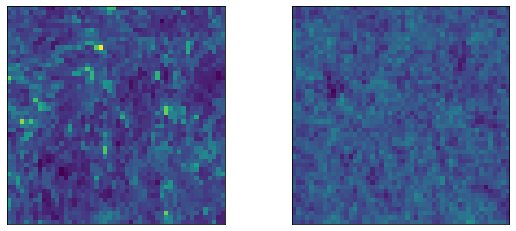

In [78]:
cutout = 1
redshift_bin = 3

global_min = min(maps[cutout,redshift_bin].min(), phase_randomized_maps[0,cutout,redshift_bin].min())
global_max = max(maps[cutout,redshift_bin].max(), phase_randomized_maps[0,cutout,redshift_bin].max())

# 3. Create a figure and a set of subplots
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
# Choose a colormap, e.g., 'viridis' or 'plasma'
cmap_name = 'viridis' 

# 4. Plot each image using the shared vmin and vmax
im1 = ax[0].imshow(maps[cutout,redshift_bin], cmap=cmap_name, vmin=global_min, vmax=global_max)
im2 = ax[1].imshow(phase_randomized_maps[0,cutout,redshift_bin], cmap=cmap_name, vmin=global_min, vmax=global_max)

# 5. (Optional) Add a single colorbar for all plots (recommended for clarity)
fig.subplots_adjust(right=0.85) # Adjust subplot region to make space for the colorbar
#cbar_ax = fig.add_axes([0.88, 0.15, 0.04, 0.7]) # Define the colorbar axis
#fig.colorbar(im1, cax=cbar_ax) # Use one of the image objects to create the colorbar

ax[0].set_xticks([])
ax[1].set_xticks([])
ax[0].set_yticks([])
ax[1].set_yticks([])
plt.savefig('Plots/gaussianized_1.pdf')
plt.show()